# Example: The Thermal Minority Game
In this example, we simulate the minority game, an agent-based model in which an odd number of agents decide to buy or sell each round and the agents on the minority side win. Each agent chooses among a few fixed strategies, and in the thermal version it makes that choice with Boltzmann probabilities set by a temperature.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Simulate one minority game:__ A minority game is a population of agents who each pick buy or sell every round with one of a few fixed strategies, and every strategy is scored by whether it would have put its agent in the minority. We simulate one game, plot the attendance, and compute the volatility of the attendance per agent.
> * __Map the phase diagram:__ The volatility per agent depends on the number of possible histories for each agent. We vary the number of agents at a fixed memory and identify the crowded phase, the minimum near the critical value, and the dilute phase.
> * __Measure the effect of temperature:__ The temperature sets how strongly an agent favors its best-scoring strategy. We vary the temperature in the crowded phase and compare the volatility with that of the greedy game and of random strategy choice.

We compare every volatility with the value for agents who flip fair coins, which is one per agent.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values.

In [2]:
# the minority game -
m = 6; # memory: the number of past minority actions every agent sees
P = 2^m; # number of possible histories (information states)
S = 2; # number of strategies each agent holds
N_crowded = 641; # number of agents in the crowded game of Tasks 1 and 3 (odd, so the attendance is never zero); α = P/N ≈ 0.1

# the simulation -
number_of_rounds = 10_000; # rounds we record in every game, after the burn-in
burn_in = 2_000; # rounds we play first and discard, so the scores move away from their starting value of zero
number_of_seeds = 3; # independent games at each setting in Tasks 2 and 3
random_seed = 5660; # fix the random numbers, so every run gives the same games
α_c = 0.3374; # critical value of α for S = 2 and very many agents (Challet, Marsili, and Zecchina, 2000)

___

## Task 1: Simulate One Minority Game
In this task, we simulate one minority game with `N_crowded` agents at temperature $T=0$, so every agent plays its best-scoring strategy, and we measure how far the attendance moves from zero from round to round.

Every round $t$ works the same way. All agents see the same information $\mu(t)$, the last $m$ minority actions, which is one of $P=2^{m}$ possible histories. Agent $i$ plays one of its $S$ strategies, and a strategy is a fixed table that assigns an action, buy ($+1$) or sell ($-1$), to each history. The attendance is the sum of the actions:

$$
A(t) = \sum_{i=1}^{N}a_{i}(t)
$$

The agents on the minority side, $-\text{sign}\,A(t)$, win. Because $N$ is odd, $A(t)$ is never zero. After the round, every strategy, played or not, gets a new score:

$$
U_{is}(t+1) = U_{is}(t) - \frac{a_{is}^{\mu(t)}A(t)}{P}
$$

where $a_{is}^{\mu(t)}$ is the action that strategy $s$ of agent $i$ assigns to the history $\mu(t)$. A strategy that would have put its agent in the minority gains score, and one that would have put it in the majority loses score. The minority action then becomes the newest entry in the history for the next round. The strategies are drawn at random once, when we build the game, and never change; only the scores, and so the agents' choices, change over time.

We measure the volatility of the attendance per agent, $\sigma^{2}/N=\langle A^{2}\rangle/N$, the average of $A(t)^{2}$ over the recorded rounds divided by the number of agents. If every agent flipped a fair coin instead, $A(t)$ would have mean zero and variance $N$, so $\sigma^{2}/N=1$. Values above 1 mean that more agents end up on the same side than with coin flips; values below 1 mean that buyers and sellers are closer to an even split.

__Simulate the game__: [The build(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/abm/#VLQuantitativeFinancePackage.build-Tuple{Type{MyThermalMinorityGameModel},%20NamedTuple}) draws the strategies of every agent at random and returns a `MyThermalMinorityGameModel`, and [the solve(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/abm/#VLQuantitativeFinancePackage.solve-Tuple{MyThermalMinorityGameModel}) plays the game. In the code below:
* We pass the number of agents, the memory `m`, the number of strategies `S`, the temperature, and a random number generator `rng` to `build(...)`.
* `solve(...)` first plays `burn_in` rounds and discards them, then records `number_of_rounds` rounds.
* The result `game::NamedTuple` holds the attendance `attendance::Vector{Int}`, the history of each round `information::Vector{Int}`, the volatility per agent `volatility_per_agent::Float64`, the number of histories per agent `alpha::Float64` ($\alpha=P/N$), and the final scores `final_scores::Array{Float64,2}`, one row per agent and one column per strategy.

Let's simulate the game:

In [3]:
game = let

    # initialize: a random number generator with a fixed seed, so every run gives the same game -
    rng = MersenneTwister(random_seed);

    # build the game: draw S random strategies for each of the N agents -
    model = build(MyThermalMinorityGameModel, (
        N = N_crowded, # number of agents (odd)
        m = m, # memory: the number of past minority actions in the history
        S = S, # strategies per agent
        temperature = 0.0, # T = 0: every agent plays its best-scoring strategy
        rng = rng # random number generator for the strategies
    ));

    # play the game: discard the burn-in rounds, then record number_of_rounds rounds -
    result = solve(model; number_of_rounds = number_of_rounds, burn_in = burn_in, rng = rng);

    # checks: one attendance per recorded round, and A(t) is odd, so never zero -
    @assert length(result.attendance) == number_of_rounds "one attendance per recorded round"
    @assert all(isodd, result.attendance) "with an odd number of agents, the attendance is odd"

    # return -
    result
end;

Let's put the size of the game and its volatility per agent in a table:

In [4]:
let

    # build the table: the size of the game and the volatility per agent -
    df = DataFrame(
        quantity = ["number of agents N", "memory m", "number of histories P = 2^m", "histories per agent α = P/N", "volatility per agent σ²/N"],
        value = [string(N_crowded), string(m), string(P), string(round(game.alpha, digits = 4)), string(round(game.volatility_per_agent, digits = 3))]
    );

    # show the table -
    pretty_table(df; column_labels = ["quantity", "value"], alignment = [:l, :r],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
end

 ----------------------------- --------
  quantity                       value 
 ----------------------------- --------
  number of agents N               641
  memory m                           6
  number of histories P = 2^m       64
  histories per agent α = P/N   0.0998
  volatility per agent σ²/N      2.804
 ----------------------------- --------


> __What do we see?__ The volatility per agent is well above 1, the value for coin flips. With many more agents than histories, the attendance moves much farther from zero than it would if every agent flipped a coin.

`Unhide` the code block below to see how we plotted the attendance for the first 200 recorded rounds. The dashed lines at $\pm\sqrt{N}$ mark one standard deviation of the attendance for coin flips.

> __What do we see?__ The attendance swings far from zero in both directions, and many rounds land outside the dashed lines, one coin-flip standard deviation from zero. Large majorities of buyers and large majorities of sellers both occur, often within a few rounds of each other.

How does the attendance move from round to round?

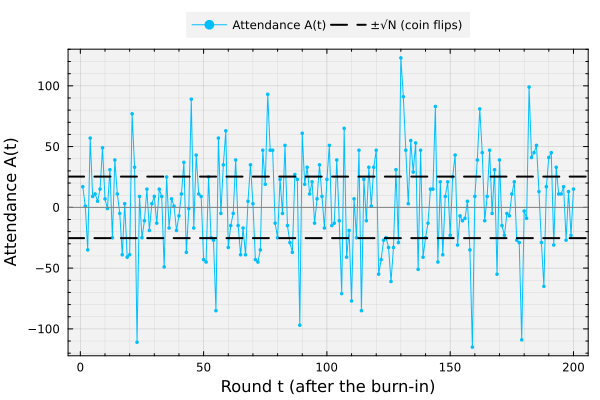

In [5]:
let

    # initialize: the first 200 recorded rounds -
    window = 1:200; # rounds to plot
    A = game.attendance[window]; # attendance A(t) in those rounds
    band = sqrt(N_crowded); # one standard deviation of the attendance for coin flips

    # plot: the attendance in each round -
    plot(window, A, lw = 1, c = :deepskyblue1, marker = :circle, ms = 2, msw = 0, label = "Attendance A(t)",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :outertop, legend_columns = 2)
    hline!([band, -band], lw = 2, c = :black, ls = :dash, label = "±√N (coin flips)") # one standard deviation for coin flips
    hline!([0.0], lw = 1, c = :gray, label = "") # an even split between buyers and sellers

    # labels -
    xlabel!("Round t (after the burn-in)", fontsize = 18)
    ylabel!("Attendance A(t)", fontsize = 18)
end

### Choosing a strategy at a finite temperature
So far, every agent played its best-scoring strategy. In the thermal game, agent $i$ instead plays strategy $s$ with the Boltzmann probability:

$$
p_{is} = \frac{\exp\left(U_{is}/T\right)}{\displaystyle\sum_{k=1}^{S}\exp\left(U_{ik}/T\right)}
$$

where $T\geq 0$ is the temperature, measured in the same units as the scores. The lecture derives this rule by maximizing the entropy of the choice probabilities for a fixed expected score. At $T=0$ the agent always plays its best strategy, and as $T\to\infty$ it picks each of its $S$ strategies with probability $1/S$, whatever the scores. What matters in between is the temperature compared with the gap between the scores.

[The boltzmann_weights(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/abm/#VLQuantitativeFinancePackage.boltzmann_weights) computes these probabilities. Let's apply it to the final scores of one agent whose two scores differ, at temperatures from zero to infinity, with the finite ones set to multiples of that agent's score gap $\Delta=|U_{i1}-U_{i2}|$:

In [6]:
let

    # initialize: the first agent whose two final scores differ, and its score gap -
    i = findfirst(k -> game.final_scores[k, 1] != game.final_scores[k, 2], 1:N_crowded); # agent index
    U = game.final_scores[i, :]; # final scores of agent i's strategies
    Δ = abs(U[1] - U[2]); # score gap
    println("agent i = $(i): scores U = $(round.(U, digits = 2)), score gap Δ = $(round(Δ, digits = 2))");

    # compute the Boltzmann probabilities at each temperature -
    temperatures = [0.0, 0.1*Δ, Δ, 10*Δ, Inf]; # T = 0, three multiples of the score gap, and T = ∞
    probabilities = [boltzmann_weights(U, T) for T ∈ temperatures]; # one probability vector per temperature

    # build the table: one row per temperature -
    df = DataFrame(
        T_over_Δ = ["0", "0.1", "1", "10", "∞"],
        T = temperatures,
        p1 = [p[1] for p ∈ probabilities],
        p2 = [p[2] for p ∈ probabilities]
    );
    pretty_table(df; column_labels = ["T/Δ", "temperature T", "p(strategy 1)", "p(strategy 2)"], alignment = [:r, :r, :r, :r],
        formatters = [fmt__printf("%.2f", [2]), fmt__printf("%.4f", [3, 4])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: every row is a probability distribution -
    @assert all(p -> isapprox(sum(p), 1.0) && all(≥(0.0), p), probabilities) "each row must sum to 1"
end

agent i = 1: scores U = [-1.06, -5.91], score gap Δ = 4.84
 ----- --------------- --------------- ---------------
  T/Δ   temperature T   p(strategy 1)   p(strategy 2) 
 ----- --------------- --------------- ---------------
    0            0.00          1.0000          0.0000
  0.1            0.48          1.0000          0.0000
    1            4.84          0.7311          0.2689
   10           48.44          0.5250          0.4750
    ∞             Inf          0.5000          0.5000
 ----- --------------- --------------- ---------------


> __What do we see?__ At $T=0$ and at a tenth of the score gap, the agent plays its better strategy with probability 1 to four decimal places. When the temperature equals the score gap, it still plays the better strategy about 73% of the time, and at ten times the gap the two probabilities are close to 1/2, the $T=\infty$ row. The probabilities depend only on $T/\Delta$, so this table is the same for any agent whose two scores differ.

Your numbers will differ if you change the constants.
___

## Task 2: Map the Phase Diagram
In this task, we hold the memory at $m=6$, so $P=64$ histories, and vary the number of agents $N$ to see how the volatility per agent depends on the number of histories per agent, $\alpha=P/N$.

Why this ratio? Every agent adapts by playing whichever of its strategies has the best score, and every score is updated with the same attendance. When $\alpha$ is small, there are many agents for each history, and many of them switch to the same action at the same time, which moves the attendance far from zero, as we saw in Task 1. When $\alpha$ is large, each strategy is a long table, and the agents' choices barely affect each other's scores. [Challet, Marsili, and Zecchina (2000)](https://doi.org/10.1103/PhysRevLett.84.1824) showed that, for $S=2$ strategies and very many agents, the volatility per agent has its minimum at the critical value $\alpha_{c}\approx 0.3374$, where the game goes through a phase transition. A phase transition is a sharp change in the collective behavior of a large system when a parameter crosses a critical value, as when water freezes at 0 °C. We call the region $\alpha<\alpha_{c}$ the crowded phase and the region $\alpha>\alpha_{c}$ the dilute phase. Our games have at most about a thousand agents, so we expect the minimum near $\alpha_{c}$, not exactly at it.

__Sweep the number of agents__: For each $N$, we build and play `number_of_seeds` independent games at $T=0$ and record each game's volatility per agent. In the code below:
* The list `agent_counts::Vector{Int}` holds odd numbers of agents from 21 to 1,001, with extra values from 151 to 251, near $N\approx P/\alpha_{c}\approx 190$, where we expect the minimum.
* One random number generator `rng`, seeded with `random_seed`, supplies the strategies and the choices in every game, so each game is different but the whole sweep is reproducible.
* The result `phase_df::DataFrame` has one row per game: the number of agents, $\alpha$, the seed index, and $\sigma^{2}/N$.

Let's run the sweep:

In [7]:
phase_df = let

    # initialize: odd numbers of agents, denser near N ≈ P/α_c, and one random number generator for the whole sweep -
    agent_counts = [21, 41, 61, 81, 101, 121, 141, 151:10:251..., 281, 321, 401, 501, 641, 801, 1001]; # numbers of agents N (all odd)
    rng = MersenneTwister(random_seed); # reproducible sweep
    df = DataFrame(N = Int[], alpha = Float64[], seed = Int[], volatility = Float64[]); # one row per game

    # main loop: number_of_seeds games for every number of agents -
    for N ∈ agent_counts
        for k ∈ 1:number_of_seeds
            model = build(MyThermalMinorityGameModel, (N = N, m = m, S = S, temperature = 0.0, rng = rng)); # new random strategies
            result = solve(model; number_of_rounds = number_of_rounds, burn_in = burn_in, rng = rng); # play the game
            push!(df, (N, result.alpha, k, result.volatility_per_agent)); # store α and σ²/N
        end
    end

    # checks: every number of agents is odd, and one row per game -
    @assert all(isodd, agent_counts) "the number of agents must be odd"
    @assert nrow(df) == length(agent_counts)*number_of_seeds "one row per game"

    # return -
    df
end;

For each number of agents, we average the volatility per agent over the games. Where does the smallest average fall, compared with the cited critical value?

In [8]:
phase_mean_df = let

    # initialize: the average of σ²/N over the games at each number of agents -
    df = combine(groupby(phase_df, [:N, :alpha], sort = true), :volatility => mean => :mean_volatility); # one row per N
    sort!(df, :alpha); # increasing α
    j = argmin(df.mean_volatility); # row with the smallest average volatility

    # show the minimum: simulated, next to the cited critical value -
    summary_df = DataFrame(
        quantity = ["α at the smallest average σ²/N (simulated)", "smallest average σ²/N (simulated)", "number of agents there", "critical value α_c (Challet, Marsili, and Zecchina)"],
        value = [string(round(df.alpha[j], digits = 4)), string(round(df.mean_volatility[j], digits = 3)), string(df.N[j]), string(α_c)]
    );
    pretty_table(summary_df; column_labels = ["quantity", "value"], alignment = [:l, :r],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: one row per number of agents -
    @assert nrow(df) == length(unique(phase_df.N)) "one row per number of agents"

    # return -
    df
end;

 ----------------------------------------------------- --------
  quantity                                               value 
 ----------------------------------------------------- --------
  α at the smallest average σ²/N (simulated)            0.3536
  smallest average σ²/N (simulated)                      0.142
  number of agents there                                   181
  critical value α_c (Challet, Marsili, and Zecchina)   0.3374
 ----------------------------------------------------- --------


> __What do we see?__ The smallest average volatility in our sweep is far below 1, and it falls at a value of $\alpha$ close to the cited critical value $\alpha_{c}$. With at most about a thousand agents and three games at each $N$, we do not expect to recover $\alpha_{c}$ exactly.

`Unhide` the code block below to see how we plotted the phase diagram: the volatility per agent against $\alpha$ on log axes, one faint point per game and a line through the averages.

> __What do we see?__
>
> * __Crowded phase:__ For the smallest values of $\alpha$, the volatility per agent is above the coin-flip line and grows as $\alpha$ falls. Here, the attendance swings farther from zero than if every agent flipped a coin.
> * __Near the critical value:__ The volatility per agent drops below the coin-flip line around $\alpha=0.2$ and reaches its minimum near the dotted line at $\alpha_{c}$. The games at the same $\alpha$ differ most just below $\alpha_{c}$, where some fall far below the average.
> * __Dilute phase:__ For $\alpha$ above the minimum, the volatility per agent rises again toward the coin-flip line, but it is still below that line at the largest $\alpha$ we tried.

How does the volatility per agent depend on the number of histories per agent?

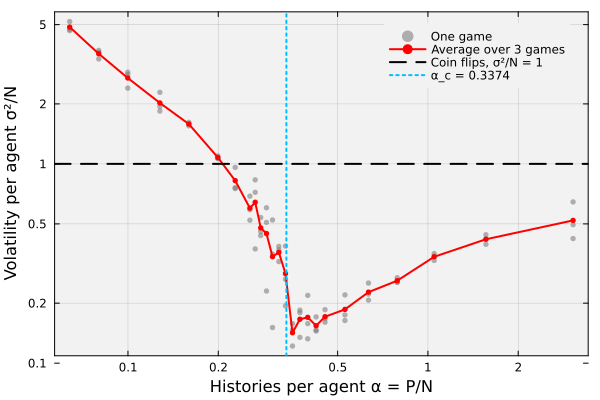

In [9]:
let

    # plot: one faint point per game, and the averages over the games -
    scatter(phase_df.alpha, phase_df.volatility, ms = 3, msw = 0, c = :gray50, alpha = 0.6, label = "One game",
        xscale = :log10, yscale = :log10,
        xticks = ([0.1, 0.2, 0.5, 1.0, 2.0], ["0.1", "0.2", "0.5", "1", "2"]), # plain tick labels on the log axes
        yticks = ([0.1, 0.2, 0.5, 1.0, 2.0, 5.0], ["0.1", "0.2", "0.5", "1", "2", "5"]),
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topright)
    plot!(phase_mean_df.alpha, phase_mean_df.mean_volatility, lw = 2, c = :red, marker = :circle, ms = 3, msw = 0,
        label = "Average over $(number_of_seeds) games") # the averages
    hline!([1.0], lw = 2, c = :black, ls = :dash, label = "Coin flips, σ²/N = 1") # agents who flip fair coins
    vline!([α_c], lw = 2, c = :deepskyblue1, ls = :dot, label = "α_c = $(α_c)") # cited critical value

    # labels -
    xlabel!("Histories per agent α = P/N", fontsize = 18)
    ylabel!("Volatility per agent σ²/N", fontsize = 18)
end

Your numbers will differ if you change the constants. Try `m = 5` or `m = 7` and compare the curves plotted against $\alpha$.
___

## Task 3: Measure the Effect of Temperature
In this task, we return to the crowded game of Task 1, with `N_crowded` agents and $\alpha\approx 0.1$, and vary the temperature $T$ of the Boltzmann choice rule.

At $T=0$, we have the greedy game of Task 1, with a volatility per agent above 1. As $T\to\infty$, every agent picks each of its two strategies with probability 1/2 every round, whatever the scores. [Cavagna, Garrahan, Giardina, and Sherrington (1999)](https://doi.org/10.1103/PhysRevLett.83.4429) found that between these two limits there is a range of temperatures where the volatility falls below the value for random choice. Our scores are divided by $P$ (the scaling of Challet, Marsili, and Zecchina), while theirs are divided by $N$, so our temperature axis is on a different scale; we read where the low-volatility range lies from our own output.

__Sweep the temperature__: For each temperature, we build and play `number_of_seeds` games with `N_crowded` agents and record each game's volatility per agent. In the code below:
* `temperatures::Vector{Float64}` runs from 0.01 to 100,000 on a log grid with two values for every factor of ten, and we also play the two limits, $T=0$ and $T=\infty$.
* As in Task 2, one random number generator `rng`, seeded with `random_seed`, supplies every game.
* The result `temperature_df::DataFrame` has one row per game: the temperature, the seed index, and $\sigma^{2}/N$.

Let's run the sweep:

In [10]:
temperature_df = let

    # initialize: a log grid of temperatures plus the two limits, and one random number generator for the whole sweep -
    temperatures = [0.0; 10.0 .^ range(-2, 5, length = 15); Inf]; # T = 0, 0.01 to 100,000, and T = ∞
    rng = MersenneTwister(random_seed); # reproducible sweep
    df = DataFrame(temperature = Float64[], seed = Int[], volatility = Float64[]); # one row per game

    # main loop: number_of_seeds games at every temperature -
    for T ∈ temperatures
        for k ∈ 1:number_of_seeds
            model = build(MyThermalMinorityGameModel, (N = N_crowded, m = m, S = S, temperature = T, rng = rng)); # new random strategies
            result = solve(model; number_of_rounds = number_of_rounds, burn_in = burn_in, rng = rng); # play the game
            push!(df, (T, k, result.volatility_per_agent)); # store σ²/N
        end
    end

    # checks: one row per game -
    @assert nrow(df) == length(temperatures)*number_of_seeds "one row per game"

    # return -
    df
end;

Let's compare the greedy game, the smallest average volatility at a finite temperature, and random choice:

In [11]:
temperature_mean_df = let

    # initialize: the average of σ²/N over the games at each temperature -
    df = combine(groupby(temperature_df, :temperature, sort = true), :volatility => mean => :mean_volatility); # one row per temperature
    finite = filter(:temperature => T -> 0 < T < Inf, df); # finite, nonzero temperatures
    j = argmin(finite.mean_volatility); # finite temperature with the smallest average volatility

    # show the comparison -
    summary_df = DataFrame(
        setting = ["greedy game, T = 0", "smallest average at a finite temperature", "random choice, T = ∞"],
        temperature = [0.0, finite.temperature[j], Inf],
        mean_volatility = [only(df.mean_volatility[df.temperature .== 0.0]), finite.mean_volatility[j], only(df.mean_volatility[isinf.(df.temperature)])]
    );
    pretty_table(summary_df; column_labels = ["setting", "temperature T", "average σ²/N"], alignment = [:l, :r, :r],
        formatters = [fmt__printf("%.3f", [3])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: the grid has both limits -
    @assert any(==(0.0), df.temperature) && any(isinf, df.temperature) "the sweep must include T = 0 and T = ∞"

    # return -
    df
end;

 ------------------------------------------ --------------- --------------
  setting                                    temperature T   average σ²/N 
 ------------------------------------------ --------------- --------------
  greedy game, T = 0                                   0.0          2.723
  smallest average at a finite temperature           100.0          0.462
  random choice, T = ∞                                 Inf          1.081
 ------------------------------------------ --------------- --------------


> __What do we see?__ At the best finite temperature in our grid, the average volatility per agent is far below both the greedy game and random choice. Random choice gives a volatility per agent close to 1, the coin-flip value.

`Unhide` the code block below to see how we plotted the volatility per agent against the temperature on a log axis. The horizontal lines mark the greedy game ($T=0$), random choice ($T=\infty$), and coin flips.

> __What do we see?__
>
> * __Low temperatures:__ Up to about $T=0.3$, the volatility per agent stays near the greedy line. These temperatures are small compared with most score gaps, so, as in the table in Task 1, the agents almost always play their better strategy.
> * __Intermediate temperatures:__ Between about $T=1$ and $T=10$, the volatility per agent drops steeply and crosses the random-choice line. From about $T=10$ to $T=1{,}000$ it stays well below both the greedy line and the random-choice line, with its smallest value near $T=100$.
> * __High temperatures:__ Above about $T=1{,}000$, the volatility per agent rises slowly back toward the random-choice line.

How does the volatility per agent change with the temperature?

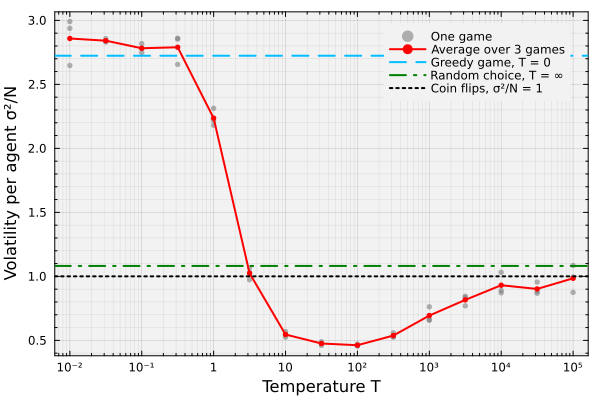

In [12]:
let

    # initialize: the finite temperatures, and the averages at the two limits -
    finite_games = filter(:temperature => T -> 0 < T < Inf, temperature_df); # games at finite, nonzero temperatures
    finite_means = filter(:temperature => T -> 0 < T < Inf, temperature_mean_df); # their averages
    greedy = only(temperature_mean_df.mean_volatility[temperature_mean_df.temperature .== 0.0]); # average σ²/N at T = 0
    random_choice = only(temperature_mean_df.mean_volatility[isinf.(temperature_mean_df.temperature)]); # average σ²/N at T = ∞

    # plot: one faint point per game, and the averages over the games -
    scatter(finite_games.temperature, finite_games.volatility, ms = 3, msw = 0, c = :gray50, alpha = 0.6, label = "One game",
        xscale = :log10, xticks = (10.0 .^ (-2:5), ["10⁻²", "10⁻¹", "1", "10", "10²", "10³", "10⁴", "10⁵"]), # one tick per factor of ten
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topright)
    plot!(finite_means.temperature, finite_means.mean_volatility, lw = 2, c = :red, marker = :circle, ms = 3, msw = 0,
        label = "Average over $(number_of_seeds) games") # the averages
    hline!([greedy], lw = 2, c = :deepskyblue1, ls = :dash, label = "Greedy game, T = 0") # the T = 0 limit
    hline!([random_choice], lw = 2, c = :green, ls = :dashdot, label = "Random choice, T = ∞") # the T = ∞ limit
    hline!([1.0], lw = 2, c = :black, ls = :dot, label = "Coin flips, σ²/N = 1") # agents who flip fair coins

    # labels -
    xlabel!("Temperature T", fontsize = 18)
    ylabel!("Volatility per agent σ²/N", fontsize = 18)
end

Your numbers will differ if you change the constants. Try `number_of_rounds = 20_000` and see how the right end of the curve changes: the scores keep adding up over a game, so in a longer game the score gaps are larger compared with the same temperature.
___

## Summary
In this example, we simulated the minority game, measured the volatility of the attendance per agent, mapped how it depends on the number of histories per agent, and measured how the temperature of the strategy choice changes it.

> __Key Takeaways:__
>
> * __A few rules produce a measurable aggregate:__ We simulated agents who each buy or sell with one of two fixed strategies, scored every strategy after each round, and recorded the attendance. The volatility of the attendance per agent let us compare the whole population with agents who flip coins.
> * __The number of histories per agent sets the volatility:__ We varied the number of agents at a fixed memory and found the crowded phase, where the volatility is above the coin-flip value, a minimum well below it near the cited critical value, and the dilute phase, where it rises toward the coin-flip value again. The same agents and rules behave differently depending only on how many agents share the histories.
> * __Temperature changes the crowded game:__ We varied the temperature of the Boltzmann choice rule at a crowded setting. Low temperatures gave the greedy game, high temperatures approached random choice, and in between the volatility fell below both limits.

The agents, the history they see, their rule for choosing a strategy, the attendance, and the scores that feed the attendance back into the next choice are the five parts of an agent-based model from the lecture.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___